In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Cluster_number -> cluster_id

In [2]:
df = pd.read_csv("data/Hit_grouped_final.csv")
hit_groups = list(df['hit_group'].unique())

In [3]:
tmp = df.loc[df['hit_group'] == 'S/WS/WN']
tmp.loc[tmp['Protein']=='PAH-WT']

,Unnamed: 0,ID,delta_Thermal_Shift,delta_Spectral_Shift,Protein,id_prot,ID_,cluster_id,protein,hit_group,delta_TS_greater_2
34,34,CSCS00058439641,0.8116,0.130749,PAH-WT,CSCS00058439641_WT,CSCS00058439641,1318.0,WT,S/WS/WN,False
56,56,CSCS00133044388,0.5411,-0.119500,PAH-WT,CSCS00133044388_WT,CSCS00133044388,1882.0,WT,S/WS/WN,False
98,98,CSCS00133059449,2.9759,0.172761,PAH-WT,CSCS00133059449_WT,CSCS00133059449,1605.0,WT,S/WS/WN,True
129,129,CSCS00116285367,0.9920,-0.072068,PAH-WT,CSCS00116285367_WT,CSCS00116285367,3174.0,WT,S/WS/WN,False
149,149,CSCS00058923669,0.9469,0.108746,PAH-WT,CSCS00058923669_WT,CSCS00058923669,3816.0,WT,S/WS/WN,False
...,...,...,...,...,...,...,...,...,...,...,...
65527,65527,CSCS00060612293,3.6974,-0.092678,PAH-WT,CSCS00060612293_WT,CSCS00060612293,3140.0,WT,S/WS/WN,True
65564,65564,CSCS00102901624,0.8116,0.075558,PAH-WT,CSCS00102901624_WT,CSCS00102901624,1245.0,WT,S/WS/WN,False
65622,65622,CSCS00026214908,0.9018,-0.094713,PAH-WT,CSCS00026214908_WT,CSCS00026214908,1553.0,WT,S/WS/WN,False
65625,65625,CSCS00026212511,3.2465,0.096361,PAH-WT,CSCS00026212511_WT,CSCS00026212511,2784.0,WT,S/WS/WN,True


In [4]:
pd.DataFrame(tmp).to_excel('S_WS_WS_list.xlsx')

In [5]:
# Separate per group

In [6]:
c1 = df[df['protein'] == 'WT'].groupby('hit_group').count()['ID'].reindex(hit_groups, fill_value=0)
c2 = df[df['protein'] == 'I65T'].groupby('hit_group').count()['ID'].reindex(hit_groups, fill_value=0)
df_count = pd.DataFrame({
    'WT'   : c1,
    'I65T' : c2,
    'both' : 0,
    'WT_exc' : 0,
    'I65T_exc' : 0
})
# df_count

In [7]:
# intersection
for i in hit_groups:
    id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
    id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])
    df_count.loc[i, 'both'] = len(id_wt.intersection(id_i65t))
    df_count.loc[i, 'WT_exc'] = len(id_wt - id_i65t)
    df_count.loc[i, 'I65T_exc'] = len(id_i65t - id_wt)

    if i == 'S/WS/WN':
        ids = {
            'both'    : id_wt.intersection(id_i65t),
            'WT_exc'   : id_wt - id_i65t,
            'I65T_exc' : id_i65t - id_wt
        }
        df.loc[((df['ID'].isin(ids['both'])) & (df['hit_group'] == i))].reset_index().to_excel(f'S-WS-WN_both.xlsx')
        df.loc[((df['ID'].isin(ids['WT_exc'])) & (df['hit_group'] == i) & (df['protein'] == 'WT'))].reset_index().to_excel(f'S-WS-WN_WT_exc.xlsx')
        df.loc[((df['ID'].isin(ids['I65T_exc'])) & (df['hit_group'] == i) & (df['protein'] == 'I65T'))].reset_index().to_excel(f'S-WS-WN_I65T_exc.xlsx')

df_count

,WT,I65T,both,WT_exc,I65T_exc
hit_group,,,,,
WNN,8621,7836,1630,6991,6206
WNW,4291,3634,623,3668,3011
NNW,14210,12527,3590,10620,8937
NSN,2054,1734,842,1212,892
NNS,1254,0,0,1254,0
NWN,2118,3286,415,1703,2871
WSN,1204,1315,419,785,896
S/WS/WN,2221,3066,970,1251,2096
WWN,757,1368,90,667,1278


In [8]:
# First unique for cluster and then Separate per group 

In [9]:
# 'S/WS/WN' - Both

i = 'S/WS/WN'
n = 200

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])
ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

# Get df_both
df_both = df.loc[((df['ID'].isin(ids['both'])) & (df['hit_group'] == i))].reset_index()
df_both = df_both.drop_duplicates(subset='cluster_id', keep='first').reset_index()
df_both['Protein'] = 'both'
df_both['delta_TS_greater_2'].value_counts().sort_values()

delta_TS_greater_2
True      96
False    549
Name: count, dtype: int64

In [10]:
# add all delta_TS_greater_2 == True to df_final
df_both_true = df_both.loc[df_both['delta_TS_greater_2']]
df_final = df_both_true
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_both_true.shape[0]
n_true

96

104


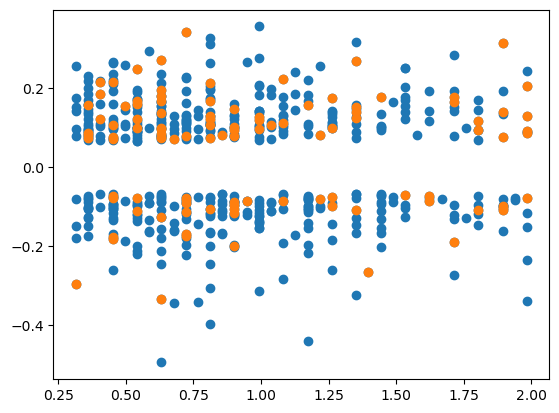

In [11]:
# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_both_false = df_both.loc[~df_both['delta_TS_greater_2']]
df_subset = df_both_false.sample(n=n_false, random_state=100)

plt.scatter(df_both_false['delta_Thermal_Shift'], df_both_false['delta_Spectral_Shift'])
plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

In [12]:
# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

df_final.shape

(73493, 11)
(69615, 11)


(200, 13)

In [13]:
# 'S/WS/WN' - WT

i = 'S/WS/WN'
n = 200

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])

ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

df_wt = df.loc[((df['ID'].isin(ids['WT_exc'])) & (df['hit_group'] == i) & (df['protein'] == 'WT'))].reset_index()
df_wt = df_wt.drop_duplicates(subset='cluster_id', keep='first').reset_index()
df_wt['delta_TS_greater_2'].value_counts().sort_values()

delta_TS_greater_2
True      60
False    604
Name: count, dtype: int64

In [14]:
# add all delta_TS_greater_2 == True to df_final
df_wt_true = df_wt.loc[df_wt['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_wt_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_wt_true.shape[0]
n_true

60

140


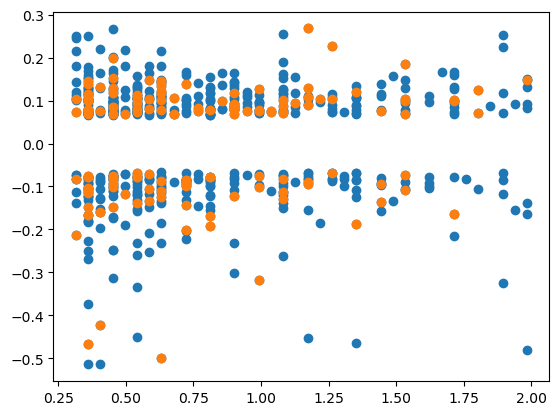

In [15]:
# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_wt_false = df_wt.loc[~df_wt['delta_TS_greater_2']]
df_subset = df_wt_false.sample(n=n_false, random_state=100)

plt.scatter(df_wt_false['delta_Thermal_Shift'], df_wt_false['delta_Spectral_Shift'])
plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

In [16]:
# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

df_final.shape

(69615, 11)
(66699, 11)


(400, 13)

In [17]:
# 'S/WS/WN' - I65T

i = 'S/WS/WN'
n = 200

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])

ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

df_mut = df.loc[((df['ID'].isin(ids['I65T_exc'])) & (df['hit_group'] == i) & (df['protein'] == 'I65T'))].reset_index()
df_mut = df_mut.drop_duplicates(subset='cluster_id', keep='first').reset_index()
df_mut['delta_TS_greater_2'].value_counts().sort_values()

delta_TS_greater_2
True      87
False    739
Name: count, dtype: int64

In [18]:
# add all delta_TS_greater_2 == True to df_final
df_mut_true = df_mut.loc[df_mut['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_mut_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_mut_true.shape[0]
n_true

87

113


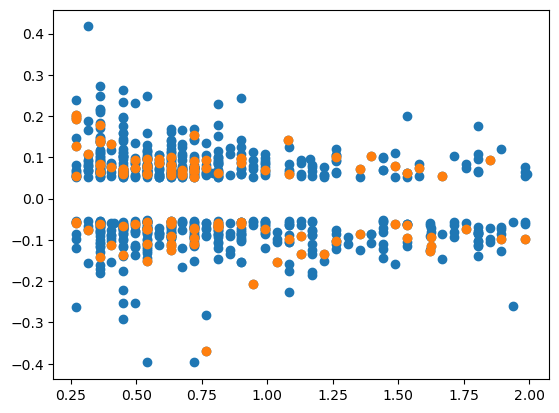

In [19]:
# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_mut_false = df_mut.loc[~df_mut['delta_TS_greater_2']]
df_subset = df_mut_false.sample(n=n_false, random_state=100)

plt.scatter(df_mut_false['delta_Thermal_Shift'], df_mut_false['delta_Spectral_Shift'])
plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

In [20]:
# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

df_final.shape

(66699, 11)
(64189, 11)


(600, 13)

In [21]:
# 'NSN' - Both

i = 'NSN'
n = 200

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])
ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

# Get df_both
df_both = df.loc[((df['ID'].isin(ids['both'])) & (df['hit_group'] == i))].reset_index()
df_both = df_both.drop_duplicates(subset='cluster_id', keep='first').reset_index()
df_both['Protein'] = 'both'
df_both['delta_TS_greater_2'].value_counts().sort_values()

delta_TS_greater_2
True      49
False    357
Name: count, dtype: int64

In [22]:
# add all delta_TS_greater_2 == True to df_final
df_both_true = df_both.loc[df_both['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_both_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_both_true.shape[0]
print(n_true)

49


In [23]:
# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_both_false = df_both.loc[~df_both['delta_TS_greater_2']]
df_subset = df_both_false.sample(n=n_false, random_state=100)

# plt.scatter(df_both_false['delta_Thermal_Shift'], df_both_false['delta_Spectral_Shift'])
# plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

151


In [24]:
# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

print(df_final.shape)

(64189, 11)
(21054, 11)
(800, 13)


In [25]:
# 'NSN' - WT

i = 'NSN'
n = 200

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])

ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

df_wt = df.loc[((df['ID'].isin(ids['WT_exc'])) & (df['hit_group'] == i) & (df['protein'] == 'WT'))].reset_index()
df_wt = df_wt.drop_duplicates(subset='cluster_id', keep='first').reset_index()
print(df_wt['delta_TS_greater_2'].value_counts().sort_values())

# add all delta_TS_greater_2 == True to df_final
df_wt_true = df_wt.loc[df_wt['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_wt_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_wt_true.shape[0]
print(n_true)

# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_wt_false = df_wt.loc[~df_wt['delta_TS_greater_2']]
df_subset = df_wt_false.sample(n=n_false, random_state=100)

# plt.scatter(df_wt_false['delta_Thermal_Shift'], df_wt_false['delta_Spectral_Shift'])
# plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

df_final.shape

delta_TS_greater_2
True      25
False    414
Name: count, dtype: int64
25
175
(21054, 11)
(18714, 11)


(1000, 13)

In [26]:
# 'NSN' - I65T

i = 'NSN'
n = 200

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])

ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

df_mut = df.loc[((df['ID'].isin(ids['I65T_exc'])) & (df['hit_group'] == i) & (df['protein'] == 'I65T'))].reset_index()
df_mut = df_mut.drop_duplicates(subset='cluster_id', keep='first').reset_index()
print(df_mut['delta_TS_greater_2'].value_counts().sort_values())

# add all delta_TS_greater_2 == True to df_final
df_mut_true = df_mut.loc[df_mut['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_mut_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_mut_true.shape[0]
print(n_true)

# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_mut_false = df_mut.loc[~df_mut['delta_TS_greater_2']]

if df_mut_false.shape[0] > n_false:
    df_subset = df_mut_false.sample(n=n_false, random_state=100)
else:
    print(f"The number of false thing is {df_mut_false.shape[0]} which < {n_false}")
    df_subset = df_mut_false

# plt.scatter(df_mut_false['delta_Thermal_Shift'], df_mut_false['delta_Spectral_Shift'])
# plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

df_final.shape

delta_TS_greater_2
True      22
False    327
Name: count, dtype: int64
22
178
(18714, 11)
(16456, 11)


(1200, 13)

In [27]:
# 'SNN' - Both

i = 'SNN'
n = 200

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])
ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

# Get df_both
df_both = df.loc[((df['ID'].isin(ids['both'])) & (df['hit_group'] == i))].reset_index()
df_both = df_both.drop_duplicates(subset='cluster_id', keep='first').reset_index()
df_both['Protein'] = 'both'
print(df_both['delta_TS_greater_2'].value_counts().sort_values())

# add all delta_TS_greater_2 == True to df_final
df_both_true = df_both.loc[df_both['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_both_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_both_true.shape[0]
print(n_true)

# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_both_false = df_both.loc[~df_both['delta_TS_greater_2']]
if df_both_false.shape[0] > n_false:
    df_subset = df_both_false.sample(n=n_false, random_state=100)
else:
    print(f"The number of false thing is {df_both_false.shape[0]} which < {n_false}")
    df_subset = df_both_false

# plt.scatter(df_both_false['delta_Thermal_Shift'], df_both_false['delta_Spectral_Shift'])
# plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

print(df_final.shape)

delta_TS_greater_2
False    61
Name: count, dtype: int64
0
200
The number of false thing is 61 which < 200
(16456, 11)
(15626, 11)
(1261, 13)


In [28]:
# 'SNN' - WT

i = 'SNN'
n = 200

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])

ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

df_wt = df.loc[((df['ID'].isin(ids['WT_exc'])) & (df['hit_group'] == i) & (df['protein'] == 'WT'))].reset_index()
df_wt = df_wt.drop_duplicates(subset='cluster_id', keep='first').reset_index()
print(df_wt['delta_TS_greater_2'].value_counts().sort_values())

# add all delta_TS_greater_2 == True to df_final
df_wt_true = df_wt.loc[df_wt['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_wt_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_wt_true.shape[0]
print(n_true)

# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_wt_false = df_wt.loc[~df_wt['delta_TS_greater_2']]
if df_wt_false.shape[0] > n_false:
    df_subset = df_wt_false.sample(n=n_false, random_state=100)
else:
    print(f"The number of false thing is {df_wt_false.shape[0]} which < {n_false}")
    df_subset = df_wt_false

# plt.scatter(df_wt_false['delta_Thermal_Shift'], df_wt_false['delta_Spectral_Shift'])
# plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

df_final.shape

delta_TS_greater_2
False    176
Name: count, dtype: int64
0
200
The number of false thing is 176 which < 200
(15626, 11)
(13893, 11)


(1437, 13)

In [29]:
# 'SNN' - I65T

i = 'SNN'
n = 200

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])

ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

df_mut = df.loc[((df['ID'].isin(ids['I65T_exc'])) & (df['hit_group'] == i) & (df['protein'] == 'I65T'))].reset_index()
df_mut = df_mut.drop_duplicates(subset='cluster_id', keep='first').reset_index()
print(df_mut['delta_TS_greater_2'].value_counts().sort_values())

# add all delta_TS_greater_2 == True to df_final
df_mut_true = df_mut.loc[df_mut['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_mut_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_mut_true.shape[0]
print(n_true)

# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_mut_false = df_mut.loc[~df_mut['delta_TS_greater_2']]

if df_mut_false.shape[0] > n_false:
    df_subset = df_mut_false.sample(n=n_false, random_state=100)
else:
    print(f"The number of false thing is {df_mut_false.shape[0]} which < {n_false}")
    df_subset = df_mut_false

# plt.scatter(df_mut_false['delta_Thermal_Shift'], df_mut_false['delta_Spectral_Shift'])
# plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

df_final.shape

delta_TS_greater_2
False    124
Name: count, dtype: int64
0
200
The number of false thing is 124 which < 200
(13893, 11)
(12822, 11)


(1561, 13)

In [30]:
200 - 61

139

In [31]:
# 'WNN' - Both

i = 'WNN'
n = 139

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])
ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

# Get df_both
df_both = df.loc[((df['ID'].isin(ids['both'])) & (df['hit_group'] == i))].reset_index()
df_both = df_both.drop_duplicates(subset='cluster_id', keep='first').reset_index()
df_both['Protein'] = 'both'
print(df_both['delta_TS_greater_2'].value_counts().sort_values())

# add all delta_TS_greater_2 == True to df_final
df_both_true = df_both.loc[df_both['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_both_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_both_true.shape[0]
print(n_true)

# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_both_false = df_both.loc[~df_both['delta_TS_greater_2']]
if df_both_false.shape[0] > n_false:
    df_subset = df_both_false.sample(n=n_false, random_state=100)
else:
    print(f"The number of false thing is {df_both_false.shape[0]} which < {n_false}")
    df_subset = df_both_false

# plt.scatter(df_both_false['delta_Thermal_Shift'], df_both_false['delta_Spectral_Shift'])
# plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

print(df_final.shape)

delta_TS_greater_2
False    125
Name: count, dtype: int64
0
139
The number of false thing is 125 which < 139
(12822, 11)
(11813, 11)
(1686, 13)


In [32]:
200 - 176

24

In [33]:
# 'WNN' - WT

i = 'WNN'
n = 24

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])

ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

df_wt = df.loc[((df['ID'].isin(ids['WT_exc'])) & (df['hit_group'] == i) & (df['protein'] == 'WT'))].reset_index()
df_wt = df_wt.drop_duplicates(subset='cluster_id', keep='first').reset_index()
print(df_wt['delta_TS_greater_2'].value_counts().sort_values())

# add all delta_TS_greater_2 == True to df_final
df_wt_true = df_wt.loc[df_wt['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_wt_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_wt_true.shape[0]
print(n_true)

# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_wt_false = df_wt.loc[~df_wt['delta_TS_greater_2']]
if df_wt_false.shape[0] > n_false:
    df_subset = df_wt_false.sample(n=n_false, random_state=100)
else:
    print(f"The number of false thing is {df_wt_false.shape[0]} which < {n_false}")
    df_subset = df_wt_false

# plt.scatter(df_wt_false['delta_Thermal_Shift'], df_wt_false['delta_Spectral_Shift'])
# plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

df_final.shape

delta_TS_greater_2
False    483
Name: count, dtype: int64
0
24
(11813, 11)
(11710, 11)


(1710, 13)

In [34]:
200 - 124

76

In [35]:
# 'WNN' - I65T

i = 'WNN'
n = 76

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])

ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

df_mut = df.loc[((df['ID'].isin(ids['I65T_exc'])) & (df['hit_group'] == i) & (df['protein'] == 'I65T'))].reset_index()
df_mut = df_mut.drop_duplicates(subset='cluster_id', keep='first').reset_index()
print(df_mut['delta_TS_greater_2'].value_counts().sort_values())

# add all delta_TS_greater_2 == True to df_final
df_mut_true = df_mut.loc[df_mut['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_mut_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_mut_true.shape[0]
print(n_true)

# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_mut_false = df_mut.loc[~df_mut['delta_TS_greater_2']]

if df_mut_false.shape[0] > n_false:
    df_subset = df_mut_false.sample(n=n_false, random_state=100)
else:
    print(f"The number of false thing is {df_mut_false.shape[0]} which < {n_false}")
    df_subset = df_mut_false

# plt.scatter(df_mut_false['delta_Thermal_Shift'], df_mut_false['delta_Spectral_Shift'])
# plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

df_final.shape

delta_TS_greater_2
False    495
Name: count, dtype: int64
0
76
(11710, 11)
(11067, 11)


(1786, 13)

In [36]:
# 'WNW' - Both

i = 'WNW'
n = 75

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])
ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

# Get df_both
df_both = df.loc[((df['ID'].isin(ids['both'])) & (df['hit_group'] == i))].reset_index()
df_both = df_both.drop_duplicates(subset='cluster_id', keep='first').reset_index()
df_both['Protein'] = 'both'
print(df_both['delta_TS_greater_2'].value_counts().sort_values())

# add all delta_TS_greater_2 == True to df_final
df_both_true = df_both.loc[df_both['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_both_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_both_true.shape[0]
print(n_true)

# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_both_false = df_both.loc[~df_both['delta_TS_greater_2']]
if df_both_false.shape[0] > n_false:
    df_subset = df_both_false.sample(n=n_false, random_state=100)
else:
    print(f"The number of false thing is {df_both_false.shape[0]} which < {n_false}")
    df_subset = df_both_false

# plt.scatter(df_both_false['delta_Thermal_Shift'], df_both_false['delta_Spectral_Shift'])
# plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

print(df_final.shape)

delta_TS_greater_2
False    143
Name: count, dtype: int64
0
75
(11067, 11)
(10512, 11)
(1861, 13)


In [37]:
# 'SNS' - WT

i = 'SNS'
n = 100

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])

ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

df_wt = df.loc[((df['ID'].isin(ids['WT_exc'])) & (df['hit_group'] == i) & (df['protein'] == 'WT'))].reset_index()
df_wt = df_wt.drop_duplicates(subset='cluster_id', keep='first').reset_index()
print(df_wt['delta_TS_greater_2'].value_counts().sort_values())

# add all delta_TS_greater_2 == True to df_final
df_wt_true = df_wt.loc[df_wt['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_wt_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_wt_true.shape[0]
print(n_true)

# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_wt_false = df_wt.loc[~df_wt['delta_TS_greater_2']]
if df_wt_false.shape[0] > n_false:
    df_subset = df_wt_false.sample(n=n_false, random_state=100)
else:
    print(f"The number of false thing is {df_wt_false.shape[0]} which < {n_false}")
    df_subset = df_wt_false

# plt.scatter(df_wt_false['delta_Thermal_Shift'], df_wt_false['delta_Spectral_Shift'])
# plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

df_final.shape

delta_TS_greater_2
False    84
Name: count, dtype: int64
0
100
The number of false thing is 84 which < 100
(10512, 11)
(9839, 11)


(1945, 13)

In [38]:
100 - 84

16

In [39]:
# 'WNW' - WT

i = 'WNW'
n = 16

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])

ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

df_wt = df.loc[((df['ID'].isin(ids['WT_exc'])) & (df['hit_group'] == i) & (df['protein'] == 'WT'))].reset_index()
df_wt = df_wt.drop_duplicates(subset='cluster_id', keep='first').reset_index()
print(df_wt['delta_TS_greater_2'].value_counts().sort_values())

# add all delta_TS_greater_2 == True to df_final
df_wt_true = df_wt.loc[df_wt['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_wt_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_wt_true.shape[0]
print(n_true)

# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_wt_false = df_wt.loc[~df_wt['delta_TS_greater_2']]
if df_wt_false.shape[0] > n_false:
    df_subset = df_wt_false.sample(n=n_false, random_state=100)
else:
    print(f"The number of false thing is {df_wt_false.shape[0]} which < {n_false}")
    df_subset = df_wt_false

# plt.scatter(df_wt_false['delta_Thermal_Shift'], df_wt_false['delta_Spectral_Shift'])
# plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

df_final.shape

delta_TS_greater_2
False    484
Name: count, dtype: int64
0
16
(9839, 11)
(9750, 11)


(1961, 13)

In [40]:
# 'WNW' - I65T

i = 'WNW'
n = 100

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])

ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

df_mut = df.loc[((df['ID'].isin(ids['I65T_exc'])) & (df['hit_group'] == i) & (df['protein'] == 'I65T'))].reset_index()
df_mut = df_mut.drop_duplicates(subset='cluster_id', keep='first').reset_index()
print(df_mut['delta_TS_greater_2'].value_counts().sort_values())

# add all delta_TS_greater_2 == True to df_final
df_mut_true = df_mut.loc[df_mut['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_mut_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_mut_true.shape[0]
print(n_true)

# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_mut_false = df_mut.loc[~df_mut['delta_TS_greater_2']]

if df_mut_false.shape[0] > n_false:
    df_subset = df_mut_false.sample(n=n_false, random_state=100)
else:
    print(f"The number of false thing is {df_mut_false.shape[0]} which < {n_false}")
    df_subset = df_mut_false

# plt.scatter(df_mut_false['delta_Thermal_Shift'], df_mut_false['delta_Spectral_Shift'])
# plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

df_final.shape

delta_TS_greater_2
False    449
Name: count, dtype: int64
0
100
(9750, 11)
(9082, 11)


(2061, 13)

In [41]:
# 'NNW' - Both

i = 'NNW'
n = 75

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])
ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

# Get df_both
df_both = df.loc[((df['ID'].isin(ids['both'])) & (df['hit_group'] == i))].reset_index()
df_both = df_both.drop_duplicates(subset='cluster_id', keep='first').reset_index()
df_both['Protein'] = 'both'
print(df_both['delta_TS_greater_2'].value_counts().sort_values())

# add all delta_TS_greater_2 == True to df_final
df_both_true = df_both.loc[df_both['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_both_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_both_true.shape[0]
print(n_true)

# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_both_false = df_both.loc[~df_both['delta_TS_greater_2']]
if df_both_false.shape[0] > n_false:
    df_subset = df_both_false.sample(n=n_false, random_state=100)
else:
    print(f"The number of false thing is {df_both_false.shape[0]} which < {n_false}")
    df_subset = df_both_false

# plt.scatter(df_both_false['delta_Thermal_Shift'], df_both_false['delta_Spectral_Shift'])
# plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

print(df_final.shape)

delta_TS_greater_2
False    546
Name: count, dtype: int64
0
75
(9082, 11)
(8612, 11)
(2136, 13)


In [42]:
# 'NNS' - WT

i = 'NNS'
n = 100

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])

ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

df_wt = df.loc[((df['ID'].isin(ids['WT_exc'])) & (df['hit_group'] == i) & (df['protein'] == 'WT'))].reset_index()
df_wt = df_wt.drop_duplicates(subset='cluster_id', keep='first').reset_index()
print(df_wt['delta_TS_greater_2'].value_counts().sort_values())

# add all delta_TS_greater_2 == True to df_final
df_wt_true = df_wt.loc[df_wt['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_wt_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_wt_true.shape[0]
print(n_true)

# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_wt_false = df_wt.loc[~df_wt['delta_TS_greater_2']]
if df_wt_false.shape[0] > n_false:
    df_subset = df_wt_false.sample(n=n_false, random_state=100)
else:
    print(f"The number of false thing is {df_wt_false.shape[0]} which < {n_false}")
    df_subset = df_wt_false

# plt.scatter(df_wt_false['delta_Thermal_Shift'], df_wt_false['delta_Spectral_Shift'])
# plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

df_final.shape

delta_TS_greater_2
False    387
Name: count, dtype: int64
0
100
(8612, 11)
(8040, 11)


(2236, 13)

In [43]:
# 'NNW' - I65T

i = 'NNW'
n = 100

id_wt = set(df.loc[(df['protein'] == 'WT') & (df['hit_group'] == i), 'ID'])
id_i65t = set(df.loc[(df['protein'] == 'I65T') & (df['hit_group'] == i), 'ID'])

ids = {
    'both'    : id_wt.intersection(id_i65t),
    'WT_exc'   : id_wt - id_i65t,
    'I65T_exc' : id_i65t - id_wt
}

df_mut = df.loc[((df['ID'].isin(ids['I65T_exc'])) & (df['hit_group'] == i) & (df['protein'] == 'I65T'))].reset_index()
df_mut = df_mut.drop_duplicates(subset='cluster_id', keep='first').reset_index()
print(df_mut['delta_TS_greater_2'].value_counts().sort_values())

# add all delta_TS_greater_2 == True to df_final
df_mut_true = df_mut.loc[df_mut['delta_TS_greater_2']]
df_final = pd.concat([df_final, df_mut_true])
# plt.scatter(df_both_true['delta_Thermal_Shift'], df_both_true['delta_Spectral_Shift'])
n_true = df_mut_true.shape[0]
print(n_true)

# Among delta_TS_greater_2 == True, randomly select n - n_true
n_false = n - n_true
print(n_false)

df_mut_false = df_mut.loc[~df_mut['delta_TS_greater_2']]

if df_mut_false.shape[0] > n_false:
    df_subset = df_mut_false.sample(n=n_false, random_state=100)
else:
    print(f"The number of false thing is {df_mut_false.shape[0]} which < {n_false}")
    df_subset = df_mut_false

# plt.scatter(df_mut_false['delta_Thermal_Shift'], df_mut_false['delta_Spectral_Shift'])
# plt.scatter(df_subset['delta_Thermal_Shift'], df_subset['delta_Spectral_Shift'])

# Update df_final
df_final = pd.concat([df_final, df_subset])

# Remove compunds in df with cluster_ids as in df_final
print(df.shape)
df = df.loc[~df['cluster_id'].isin(df_final['cluster_id'])]
print(df.shape)

df_final.shape

delta_TS_greater_2
False    755
Name: count, dtype: int64
0
100
(8040, 11)
(7611, 11)


(2336, 13)

In [44]:
df_final

,level_0,index,Unnamed: 0,ID,delta_Thermal_Shift,delta_Spectral_Shift,Protein,id_prot,ID_,cluster_id,protein,hit_group,delta_TS_greater_2
0,0,2334,2334,CSCS00028205893,2.0742,0.103874,both,CSCS00028205893_WT,CSCS00028205893,1612.0,WT,S/WS/WN,True
5,5,2457,2457,CSCS00133070215,2.3447,0.157605,both,CSCS00133070215_WT,CSCS00133070215,1867.0,WT,S/WS/WN,True
15,16,2953,2953,CSCS00025950759,3.2465,0.185692,both,CSCS00025950759_WT,CSCS00025950759,2194.0,WT,S/WS/WN,True
16,17,5644,5644,CSCS00027319139,2.8407,0.074163,both,CSCS00027319139_WT,CSCS00027319139,2784.0,WT,S/WS/WN,True
25,27,6032,6032,CSCS00027049410,2.7956,0.154890,both,CSCS00027049410_WT,CSCS00027049410,3599.0,WT,S/WS/WN,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
433,491,52230,52230,CSCS00025988012,-0.9018,0.029027,PAH-I65T,CSCS00025988012_I65T,CSCS00025988012,3274.0,I65T,NNW,False
542,654,58204,58204,CSCS00028273674,-3.8778,0.027519,PAH-I65T,CSCS00028273674_I65T,CSCS00028273674,280.0,I65T,NNW,False
399,449,51550,51550,CSCS00133143041,-0.5410,0.002808,PAH-I65T,CSCS00133143041_I65T,CSCS00133143041,270.0,I65T,NNW,False
225,243,43821,43821,CSCS00000790102,-6.4029,0.020951,PAH-I65T,CSCS00000790102_I65T,CSCS00000790102,3893.0,I65T,NNW,False


In [45]:
df_final.to_excel("hit_selection_PAH_v2.xlsx")

In [41]:
df.loc[df['hit_group'] == 'S/WS/WN']

,level_0,index,Unnamed: 0,ID,delta_Thermal_Shift,delta_Spectral_Shift,Protein,id_prot,ID_,cluster_id,protein,hit_group,delta_TS_greater_2
0,0,2334,2334,CSCS00028205893,2.0742,0.103874,both,CSCS00028205893_WT,CSCS00028205893,1612.0,WT,S/WS/WN,True
5,5,2457,2457,CSCS00133070215,2.3447,0.157605,both,CSCS00133070215_WT,CSCS00133070215,1867.0,WT,S/WS/WN,True
15,16,2953,2953,CSCS00025950759,3.2465,0.185692,both,CSCS00025950759_WT,CSCS00025950759,2194.0,WT,S/WS/WN,True
16,17,5644,5644,CSCS00027319139,2.8407,0.074163,both,CSCS00027319139_WT,CSCS00027319139,2784.0,WT,S/WS/WN,True
25,27,6032,6032,CSCS00027049410,2.7956,0.154890,both,CSCS00027049410_WT,CSCS00027049410,3599.0,WT,S/WS/WN,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
240,442,43259,43259,CSCS00058848126,0.7666,0.063918,PAH-I65T,CSCS00058848126_I65T,CSCS00058848126,3154.0,I65T,S/WS/WN,False
524,1022,56781,56781,CSCS00106477172,1.4428,-0.052829,PAH-I65T,CSCS00106477172_I65T,CSCS00106477172,880.0,I65T,S/WS/WN,False
569,1126,59441,59441,CSCS00028222899,0.5411,-0.086424,PAH-I65T,CSCS00028222899_I65T,CSCS00028222899,1989.0,I65T,S/WS/WN,False
756,1605,71799,71799,CSCS00027691554,0.4509,-0.065977,PAH-I65T,CSCS00027691554_I65T,CSCS00027691554,496.0,I65T,S/WS/WN,False
